In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
url = (
    "https://archive.ics.uci.edu/"
    "ml/machine-learning-databases/00267/"
    "data_banknote_authentication.txt"
)

columns = [
    "Variance",
    "Skewness",
    "Curtosis",
    "Entropy",
    "Class"
]

df = pd.read_csv(url, header=None, names=columns)

print("Dataset loaded successfully!")
print(df.head())

Dataset loaded successfully!
   Variance  Skewness  Curtosis  Entropy  Class
0   3.62160    8.6661   -2.8073 -0.44699      0
1   4.54590    8.1674   -2.4586 -1.46210      0
2   3.86600   -2.6383    1.9242  0.10645      0
3   3.45660    9.5228   -4.0112 -3.59440      0
4   0.32924   -4.4552    4.5718 -0.98880      0


In [4]:
# Dataset dimensions
print("Rows and columns:", df.shape)

# Column names and data types
print("\nDataset information:")
df.info()

# Statistical summary
print("\nStatistical summary:")
print(df.describe())

# Missing values
print("\nMissing values:")
print(df.isnull().sum())

# Duplicate records
print("\nDuplicate rows:", df.duplicated().sum())

# Target class distribution
print("\nClass distribution:")
print(df["Class"].value_counts())

Rows and columns: (1372, 5)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Variance  1372 non-null   float64
 1   Skewness  1372 non-null   float64
 2   Curtosis  1372 non-null   float64
 3   Entropy   1372 non-null   float64
 4   Class     1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB

Statistical summary:
          Variance     Skewness     Curtosis      Entropy        Class
count  1372.000000  1372.000000  1372.000000  1372.000000  1372.000000
mean      0.433735     1.922353     1.397627    -1.191657     0.444606
std       2.842763     5.869047     4.310030     2.101013     0.497103
min      -7.042100   -13.773100    -5.286100    -8.548200     0.000000
25%      -1.773000    -1.708200    -1.574975    -2.413450     0.000000
50%       0.496180     2.319650     0.616630    -0.586650     0.000000
7

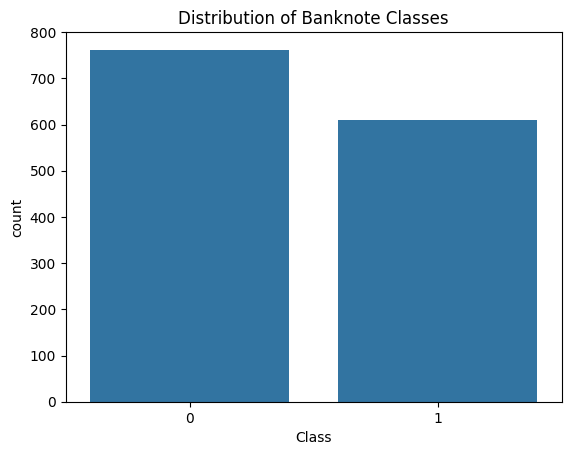

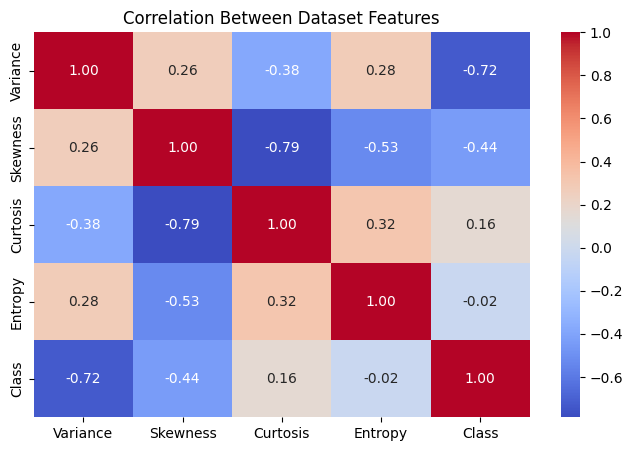

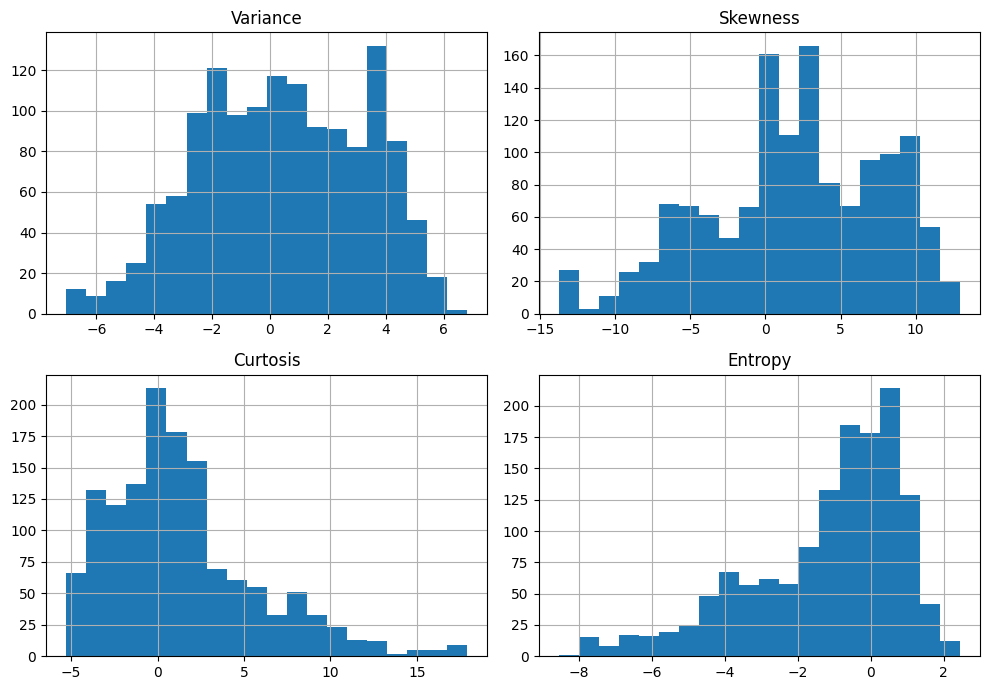

In [5]:
# Distribution of target classes
sns.countplot(data=df, x="Class")
plt.title("Distribution of Banknote Classes")
plt.show()

# Feature correlations
plt.figure(figsize=(8, 5))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Dataset Features")
plt.show()

# Feature distributions
df[["Variance", "Skewness", "Curtosis", "Entropy"]].hist(
    figsize=(10, 7), bins=20
)
plt.tight_layout()
plt.show()

In [7]:
X = df.drop(columns=["Class"])
y = df["Class"]

print("Input features:", X.shape)
print("Target values:", y.shape)

Input features: (1372, 4)
Target values: (1372,)


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 1097
Testing records: 275


In [10]:
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    trained_models[name] = model

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, average="weighted", zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions, average="weighted", zero_division=0
        )
    })

comparison = pd.DataFrame(results)
print(comparison.round(4))

                 Model  Accuracy  Precision  Recall  F1-score
0  Logistic Regression    0.9709     0.9727  0.9709    0.9710
1        Decision Tree    0.9927     0.9928  0.9927    0.9927
2        Random Forest    0.9964     0.9964  0.9964    0.9964


Best model by test accuracy: Random Forest

Classification report:
              precision    recall  f1-score   support

           0       1.00      0.99      1.00       153
           1       0.99      1.00      1.00       122

    accuracy                           1.00       275
   macro avg       1.00      1.00      1.00       275
weighted avg       1.00      1.00      1.00       275



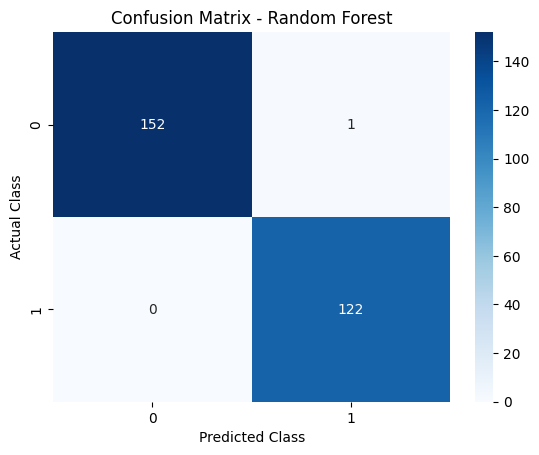

In [11]:
best_name = comparison.loc[
    comparison["Accuracy"].idxmax(), "Model"
]

best_model = trained_models[best_name]
best_predictions = best_model.predict(X_test)

print("Best model by test accuracy:", best_name)
print("\nClassification report:")
print(classification_report(y_test, best_predictions))

cm = confusion_matrix(y_test, best_predictions)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title(f"Confusion Matrix - {best_name}")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

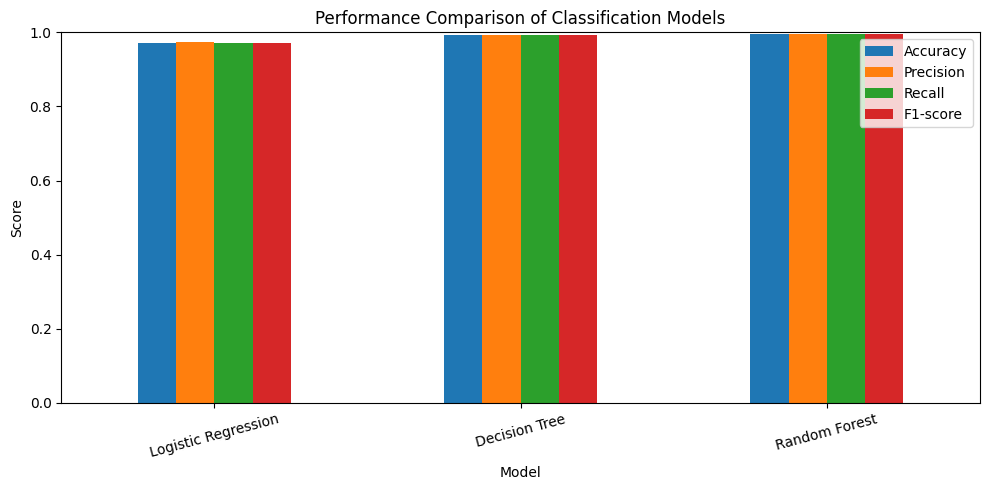

In [12]:
comparison.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-score"]
].plot(kind="bar", figsize=(10, 5), ylim=(0, 1))

plt.title("Performance Comparison of Classification Models")
plt.ylabel("Score")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()